# 01 - Explore data
Goal: understand the burglary data and the neighbourhood data before building the dataset

In [1]:
import pandas as pd # work with tables (DataFrames)
import matplotlib.pyplot as plt # make charts


In [2]:
# Load the raw burglary data saved in notebook 00 (pandas unzip the .gz file automatically)
burglary = pd.read_csv("../data/raw/47022NED_burglary_monthly_buurt.csv.gz")
print(burglary.shape) # show the number of rows and columns, should be (2607210,5)
burglary.head() # show the first 5 rows of the table

(2607210, 5)


,ID,SoortMisdrijf,WijkenEnBuurten,Perioden,GeregistreerdeMisdrijven_1
0,3274677,1.1.1,BU16800000,2012MM01,1
1,3274678,1.1.1,BU16800000,2012MM02,3
2,3274679,1.1.1,BU16800000,2012MM03,0
3,3274680,1.1.1,BU16800000,2012MM04,1
4,3274681,1.1.1,BU16800000,2012MM05,0


In [3]:
# 'Perioden' looks like '2012MM01': the first 4 characters are the year, the last 2 are the month
burglary["year"] = burglary["Perioden"].str[:4].astype(int)     # '2012MM01' -> 2012
burglary["month"] = burglary["Perioden"].str[-2:].astype(int)   # '2012MM01' -> 1

# Give the long Dutch column names short English names
burglary = burglary.rename(columns={"WijkenEnBuurten": "buurt_code",
                                    "GeregistreerdeMisdrijven_1": "burglaries"})
burglary.head()

,ID,SoortMisdrijf,buurt_code,Perioden,burglaries,year,month
0,3274677,1.1.1,BU16800000,2012MM01,1,2012,1
1,3274678,1.1.1,BU16800000,2012MM02,3,2012,2
2,3274679,1.1.1,BU16800000,2012MM03,0,2012,3
3,3274680,1.1.1,BU16800000,2012MM04,1,2012,4
4,3274681,1.1.1,BU16800000,2012MM05,0,2012,5


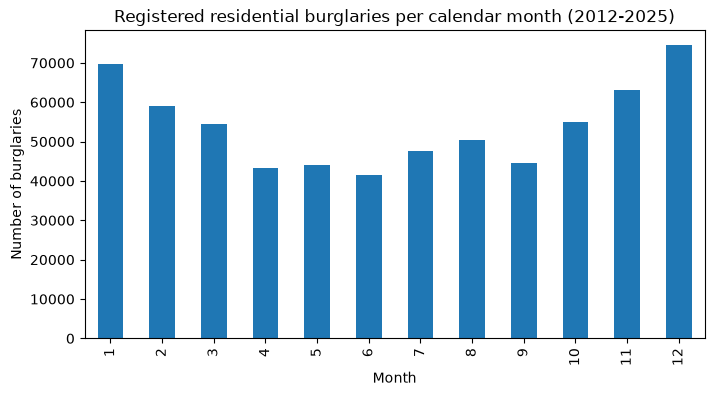

In [4]:
# Use only complete years (2026 only has January-September, which would make Oct-Dec look too low)
complete_years = burglary[burglary["year"] <= 2025]

# Total burglaries per calendar month, all years and neighbourhoods combined
per_month = complete_years.groupby("month")["burglaries"].sum()

per_month.plot(kind="bar", figsize=(8, 4))
plt.title("Registered residential burglaries per calendar month (2012-2025)")
plt.xlabel("Month")
plt.ylabel("Number of burglaries")
plt.show()

**Finding:** 
Burglaries peak in the dark months (Dec ≈ 74k, Jan ≈ 70k) and are lowest in early summer (Jun ≈ 41k). 
The dark season (Oct–Mar) accounts for roughly 58% of all burglaries. 
This supports our use case: prevention planned on 1 October for the Oct–Mar season.

In [6]:
# Keep only Amsterdam enighbourhoods: codes stat with 'BU0363' (0363 = Amsterdam's municipality code)
# .copy() makes a seperate table, so later changes to 'ams' do not affect 'burglary'
ams = burglary[burglary["buurt_code"].str.startswith("BU0363")].copy()

print(ams.shape) # expected: (91509, 7) = 517 neighbourhoods x 177 months
print(ams["buurt_code"].nunique()) # expected: 517 unique neighbourhoods

# Save the Amsterdam subset in data/processed (it's made by our code, so it does not belong in 'raw)
ams.to_csv("../data/processed/amsterdam_burglary_monthly.csv.gz", index=False)


(91509, 7)
517


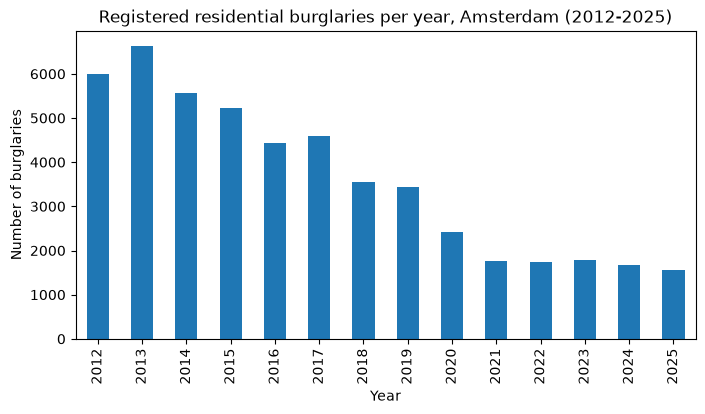

In [9]:
# Use only complete years (2026 only has January-September)
ams_complete = ams[ams["year"] <= 2025]

# Total burglaries per year in Amsterdam, all neighbourhoods combined
per_year = ams_complete.groupby("year")["burglaries"].sum()

per_year.plot(kind="bar", figsize=(8, 4))
plt.title("Registered residential burglaries per year, Amsterdam (2012-2025)")
plt.xlabel("Year")
plt.ylabel("Number of burglaries")
plt.show()

**Note**: ams --> ams_complete --> per_year
Meaning: all year --> only 2012-2025 --> sum per year

In [12]:
# Burglaries in selected years (per_year was made in the previous cell)
start = per_year.loc[2012] # start year in the dataset
pre_covid = per_year.loc[2019] # last year before Covid
end = per_year.loc[2025] # last year in the dataset

# Calculate the percentage change in burglaries (new - old) / old * 100
print("2012 -> 2025", round((end - start) / start * 100, 1), "%")
print("2012 -> 2019 (pre-Covid)", round((pre_covid - start) / start * 100, 1), "%")
print("2019 -> 2025 (post-Covid)", round((end - pre_covid) / pre_covid * 100, 1), "%")


2012 -> 2025 -74.1 %
2012 -> 2019 (pre-Covid) -42.9 %
2019 -> 2025 (post-Covid) -54.7 %


**Finding:** Registered residential burglaries in Amsterdam fell by 74.1% from 2012 to 2025.
A large part of this decline (42.9%) happened before COVID-19 (2012–2019), and burglaries kept falling
during and after COVID-19 (−54.7% from 2019 to 2025). The decline is therefore not only a COVID-19 effect.

**What this means for our project:** The data change over time (drift). A neighbourhood with 10 burglaries
was ordinary in 2014 but would be a clear outlier in 2024. Our target handles this, because a hotspot is
defined *within each season* (top 10% of Amsterdam's neighbourhoods), so there are always about 52 hotspots
regardless of the overall level. Features based on burglary counts will need the same care when we build
the dataset (notebook 02).

*Years chosen:* 2012 = first year in the dataset, 2019 = last year before COVID-19, 2025 = last complete year.

## But how sparse are the data per season?
We sum the monthly burglaries into dark seasons (Oct–Mar) to see how many burglaries a typical
neighbourhood has per season. This helps us decide on a minimum neighbourhood size and on
neighbourhood (buurt) vs. district (wijk) level.

In [14]:
# Keep only the dark-season months (October-March)
dark = ams[ams["month"].isin([10, 11, 12, 1, 2, 3])].copy()

# Name each season after the year it starts: Oct 2012 - Mar 2013 = season 2012
dark["season"] = dark["year"]                                # Oct-Dec: season = same year
dark.loc[dark["month"] <= 3, "season"] = dark["year"] - 1    # Jan-Mar: season = the year before

# Check: December 2012 and January 2013 should both be season 2012
dark[dark["Perioden"].isin(["2012MM12", "2013MM01"])].head()

,ID,SoortMisdrijf,buurt_code,Perioden,burglaries,year,month,season
164090,3481601,1.1.1,BU0363AA01,2012MM12,0,2012,12,2012
164091,3481602,1.1.1,BU0363AA01,2013MM01,0,2013,1,2012
164267,3481778,1.1.1,BU0363AA02,2012MM12,3,2012,12,2012
164268,3481779,1.1.1,BU0363AA02,2013MM01,0,2013,1,2012
164444,3481955,1.1.1,BU0363AA03,2012MM12,1,2012,12,2012


## Now we combine the months together as one single row for each neighbourhood per season

In [15]:
# Sum the six monthly numbers into one number per neighbourhood per season
per_season = dark.groupby(["buurt_code", "season"])["burglaries"].sum().reset_index()

# Drop season 2011: it only has Jan-Mar 2012, because our data starts in Jan 2012
per_season = per_season[per_season["season"] >= 2012]

print(per_season.shape) # expected: (7238, 3) = 517 neighbourhoods x 14 seasons (2012-2025)
per_season.head() # show the first 5 rows of the table

(7238, 3)


,buurt_code,season,burglaries
1,BU0363AA01,2012,0
2,BU0363AA01,2013,0
3,BU0363AA01,2014,1
4,BU0363AA01,2015,0
5,BU0363AA01,2016,0


### How many burglaries does a neighbourhood have per season?
For each season we calculate three numbers:
- **median:** burglaries in the middle neighbourhood (half have fewer, half have more)
- **share_zero:** share of neighbourhoods with 0 burglaries in the season
- **top10_threshold:** the 90th percentile, i.e. roughly how many burglaries it takes to be in the top 10% (a hotspot)

Note: these are counts, not burglaries per 1,000 dwellings. Counts show how much random noise there is,
because few events mean that chance plays a large role.

In [17]:
# True if the neighbourhood had 0 burglaries that season
per_season["zero"] = per_season["burglaries"] == 0

# One row per season with three numbers
summary = pd.DataFrame({
    "median": per_season.groupby("season")["burglaries"].median(),               # the middle neighbourhood
    "share_zero": per_season.groupby("season")["zero"].mean().round(2),          # share of neighbourhoods with 0
    "top10_threshold": per_season.groupby("season")["burglaries"].quantile(0.9)  # 10% of neighbourhoods have more and where 90% have less
})
summary

,median,share_zero,top10_threshold
season,,,
2012,5.0,0.24,20.0
2013,4.0,0.24,18.0
2014,4.0,0.24,14.0
2015,3.0,0.24,13.4
2016,3.0,0.26,13.0
2017,3.0,0.28,11.0
2018,2.0,0.29,9.0
2019,2.0,0.30,8.4
2020,1.0,0.38,5.0


**Finding:** The data become much sparser over time. In season 2012 the middle neighbourhood had 5 burglaries
and 24% of neighbourhoods had none. In our test seasons (2023–2025) the median is only 1 burglary,
37–43% of neighbourhoods have none, and about 4–5 burglaries are enough to be in the top 10%.

**What this means for our project:**
- **Noisy target:** with so few burglaries, chance plays a large role in which neighbourhoods become hotspots.
  A neighbourhood can move in or out of the top 10% because of one or two burglaries. This limits how well
  *any* model can predict, and we will discuss it as a limitation.
- **Small neighbourhoods are the biggest problem:** our target uses burglaries per 1,000 dwellings, so in a
  neighbourhood with few dwellings, 1–2 burglaries can give a very high rate. We will therefore set a
  minimum number of dwellings (decided in step 4, when we have dwelling counts from CBS).